# EDA: Campus Gym Crowdedness

Exploratory analysis of `data/gymData.csv` (about 62.5k readings taken roughly every 10 minutes). The notebook looks at:

1. Raw data: columns, sampling rate, distributions
2. Cleaning: sensor outages and missing hours after `load_hourly()`
3. Seasonality by hour of day and day of week
4. Calendar effects: semester, start of semester, holidays, weekends
5. Temperature
6. Long-term trend and the train/val/test splits
7. Autocorrelation (why the AR models use lags 24, 168 and 336)

Every figure is also saved to `results/eda/`.

In [2]:
! pip install seaborn


  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)


In [3]:
import os, sys
from pathlib import Path

# Run from the project root so src/ imports and data/ paths work
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

from src.data import (load_hourly, mask_outages, split, TRAIN_END, VAL_START, VAL_END,
                      TEST_START, TEST_END, EVAL_HOURS, FLAGS)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
FIG_DIR = Path("results/eda")
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

DOW_NAMES = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]

## 1. Raw data

In [4]:
raw = pd.read_csv("data/gymData.csv")
raw["dt"] = pd.to_datetime(raw["date"].str[:19])   # local time, same parsing as load_hourly
raw = raw.sort_values("dt").set_index("dt")

print(raw.shape)
print(f"Date range: {raw.index.min()}  ->  {raw.index.max()}")
raw.head()

(62184, 11)
Date range: 2015-08-14 17:00:11  ->  2017-03-18 19:22:51


,number_people,date,timestamp,day_of_week,is_weekend,is_holiday,temperature,is_start_of_semester,is_during_semester,month,hour
dt,,,,,,,,,,,
2015-08-14 17:00:11,37,2015-08-14 17:00:11-07:00,61211,4,0,0,71.76,0,0,8,17
2015-08-14 17:20:14,45,2015-08-14 17:20:14-07:00,62414,4,0,0,71.76,0,0,8,17
2015-08-14 17:30:15,40,2015-08-14 17:30:15-07:00,63015,4,0,0,71.76,0,0,8,17
2015-08-14 17:40:16,44,2015-08-14 17:40:16-07:00,63616,4,0,0,71.76,0,0,8,17
2015-08-14 17:50:17,45,2015-08-14 17:50:17-07:00,64217,4,0,0,71.76,0,0,8,17


In [5]:
raw.drop(columns=["date"]).describe().T

,count,mean,std,min,25%,50%,75%,max
number_people,62184.0,29.072543,22.689026,0.00,9.0,28.00,43.00,145.00
timestamp,62184.0,45799.437958,24211.275891,0.00,26624.0,46522.50,66612.00,86399.00
day_of_week,62184.0,2.982504,1.996825,0.00,1.0,3.00,5.00,6.00
is_weekend,62184.0,0.282870,0.450398,0.00,0.0,0.00,1.00,1.00
is_holiday,62184.0,0.002573,0.050660,0.00,0.0,0.00,0.00,1.00
temperature,62184.0,58.557108,6.316396,38.14,55.0,58.34,62.28,87.17
is_start_of_semester,62184.0,0.078831,0.269476,0.00,0.0,0.00,0.00,1.00
is_during_semester,62184.0,0.660218,0.473639,0.00,0.0,1.00,1.00,1.00
month,62184.0,7.439824,3.445069,1.00,5.0,8.00,10.00,12.00
hour,62184.0,12.236460,6.717631,0.00,7.0,12.00,18.00,23.00


In [6]:
print("Missing values per column:")
print(raw.isna().sum())

# How often is the sensor read?
step_min = raw.index.to_series().diff().dt.total_seconds().div(60)
print("\nMinutes between readings:")
print(step_min.describe(percentiles=[.05, .25, .5, .75, .95, .99]))
print(f"\nGaps longer than 1 hour: {(step_min > 60).sum()}")
print(f"Gaps longer than 1 day:  {(step_min > 60*24).sum()}")

Missing values per column:
number_people           0
date                    0
timestamp               0
day_of_week             0
is_weekend              0
is_holiday              0
temperature             0
is_start_of_semester    0
is_during_semester      0
month                   0
hour                    0
dtype: int64

Minutes between readings:
count    62183.000000
mean        13.479933
std        167.573834
min          0.033333
5%          10.000000
25%         10.016667
50%         10.033333
75%         10.083333
95%         19.950000
99%         20.650000
max      36031.183333
Name: dt, dtype: float64

Gaps longer than 1 hour: 374
Gaps longer than 1 day:  6


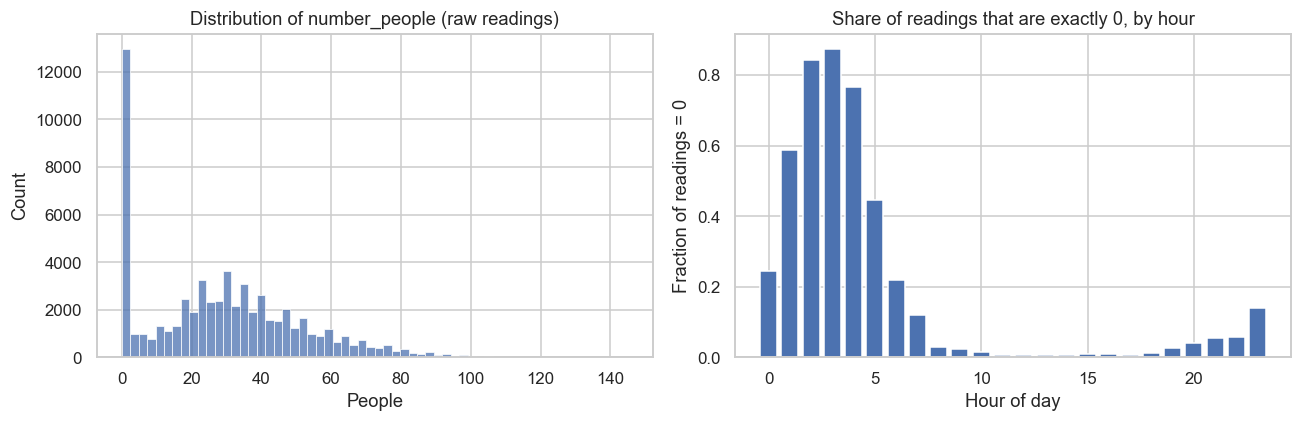

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(raw["number_people"], bins=60, ax=axes[0])
axes[0].set(title="Distribution of number_people (raw readings)", xlabel="People", ylabel="Count")

zero_share = raw["number_people"].eq(0).groupby(raw.index.hour).mean()
axes[1].bar(zero_share.index, zero_share.values)
axes[1].set(title="Share of readings that are exactly 0, by hour", xlabel="Hour of day",
            ylabel="Fraction of readings = 0")
fig.tight_layout(); save(fig, "01_raw_distribution")

Most zeros fall overnight while the gym is closed. Zeros in the middle of the day are more likely sensor outages, which is what `mask_outages()` targets.

## 2. Cleaning: outages and missing hours

In [8]:
masked = mask_outages(raw)
n_masked = masked["number_people"].isna().sum() - raw["number_people"].isna().sum()
print(f"Readings set to NaN by mask_outages: {n_masked} ({n_masked / len(raw):.2%})")

hourly = load_hourly()
print(f"\nHourly rows: {len(hourly)}")
print(f"Hours with no reading at all (number_people NaN): {hourly['number_people'].isna().sum()}")
print(f"Hours still NaN after short-gap interpolation (y NaN): {hourly['y'].isna().sum()}")
print(f"Hours filled by interpolation: {hourly['number_people'].isna().sum() - hourly['y'].isna().sum()}")

Readings set to NaN by mask_outages: 238 (0.38%)

Hourly rows: 13971
Hours with no reading at all (number_people NaN): 2378
Hours still NaN after short-gap interpolation (y NaN): 2337
Hours filled by interpolation: 41


Days with the most masked readings:
2016-11-04    92
2016-02-23    48
2015-12-25    34
2016-11-03    31
2016-03-07    28
2016-02-24     5
2015-08-14     0
2016-08-06     0
2016-08-07     0
2016-08-08     0
Name: number_people, dtype: int64


/var/folders/b7/jgt2vtf55dv3gx2t74rdh2h00000gn/T/ipykernel_4759/573100262.py:9: DeprecationWarning: The 'generic' unit for NumPy timedelta is deprecated, and will raise an error in the future. This includes implicit conversion of bare integers (e.g. `+ 1`). Please use a specific unit instead.
  win = slice(day - pd.Timedelta(days=1), day + pd.Timedelta(days=2))


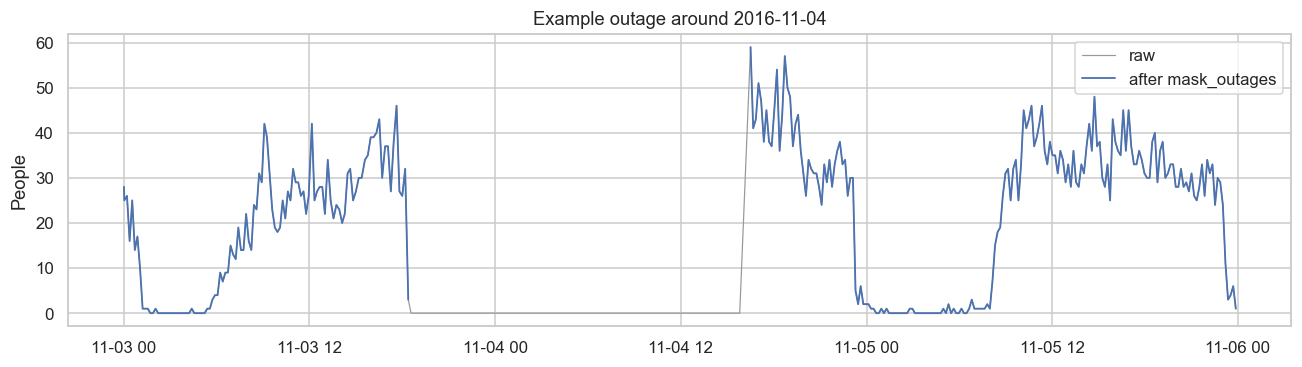

In [9]:
# Where are the masked outages? Show raw vs. masked around the largest outage.
was_masked = masked["number_people"].isna() & raw["number_people"].notna()
masked_days = was_masked.groupby(raw.index.date).sum().sort_values(ascending=False)
print("Days with the most masked readings:")
print(masked_days.head(10))

if len(masked_days) and masked_days.iloc[0] > 0:
    day = pd.Timestamp(masked_days.index[0])
    win = slice(day - pd.Timedelta(days=1), day + pd.Timedelta(days=2))
    fig, ax = plt.subplots(figsize=(12, 3.5))
    ax.plot(raw.loc[win, "number_people"], lw=0.8, color="0.6", label="raw")
    ax.plot(masked.loc[win, "number_people"], lw=1.2, label="after mask_outages")
    ax.set(title=f"Example outage around {day.date()}", ylabel="People")
    ax.legend(); fig.tight_layout(); save(fig, "02_outage_example")

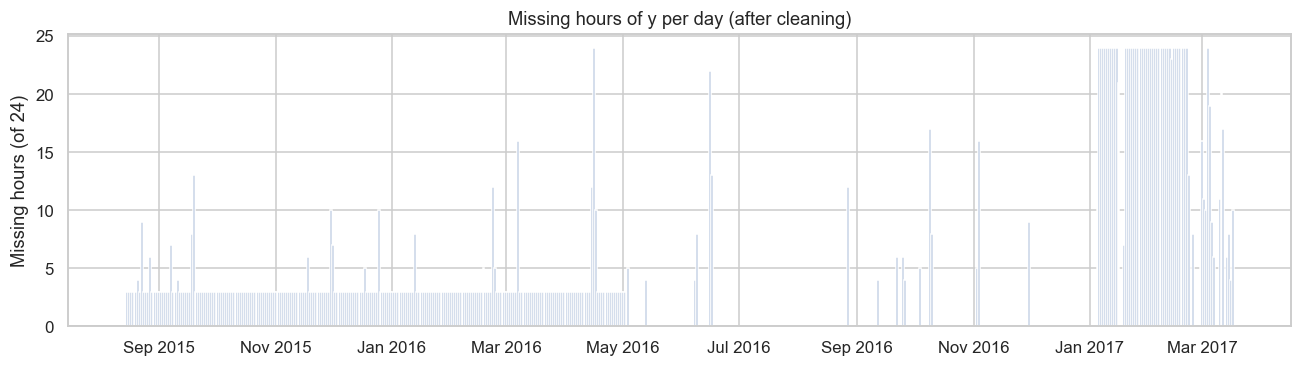

In [10]:
# Missing y per day across the full series
miss_daily = hourly["y"].isna().resample("D").sum()

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.bar(miss_daily.index, miss_daily.values, width=1.0)
ax.set(title="Missing hours of y per day (after cleaning)", ylabel="Missing hours (of 24)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.tight_layout(); save(fig, "03_missing_per_day")

## 3. Seasonality: hour of day and day of week

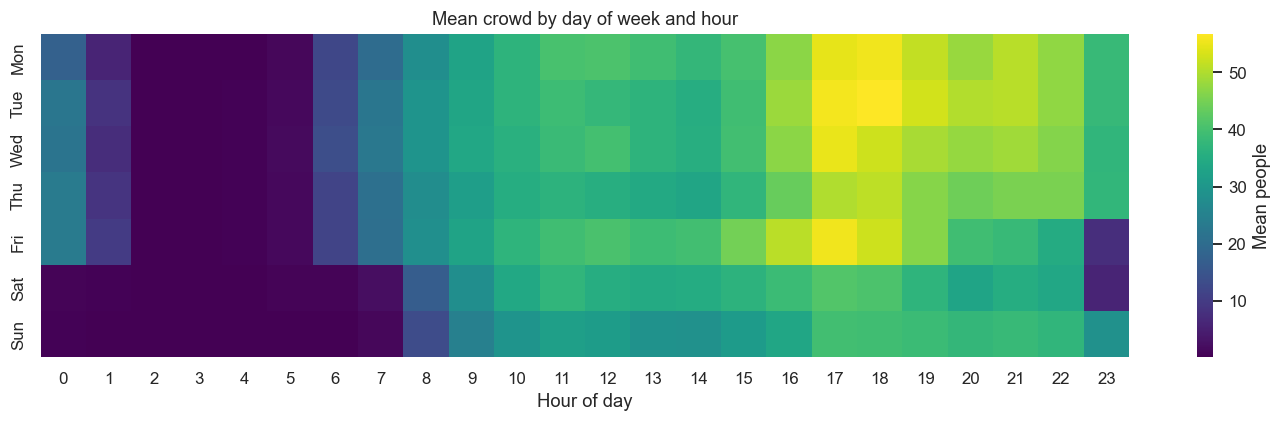

In [11]:
pivot = hourly.pivot_table(index="dow", columns="hour", values="y", aggfunc="mean")
pivot.index = DOW_NAMES

fig, ax = plt.subplots(figsize=(13, 4))
sns.heatmap(pivot, cmap="viridis", ax=ax, cbar_kws={"label": "Mean people"})
ax.set(title="Mean crowd by day of week and hour", xlabel="Hour of day", ylabel="")
fig.tight_layout(); save(fig, "04_heatmap_dow_hour")

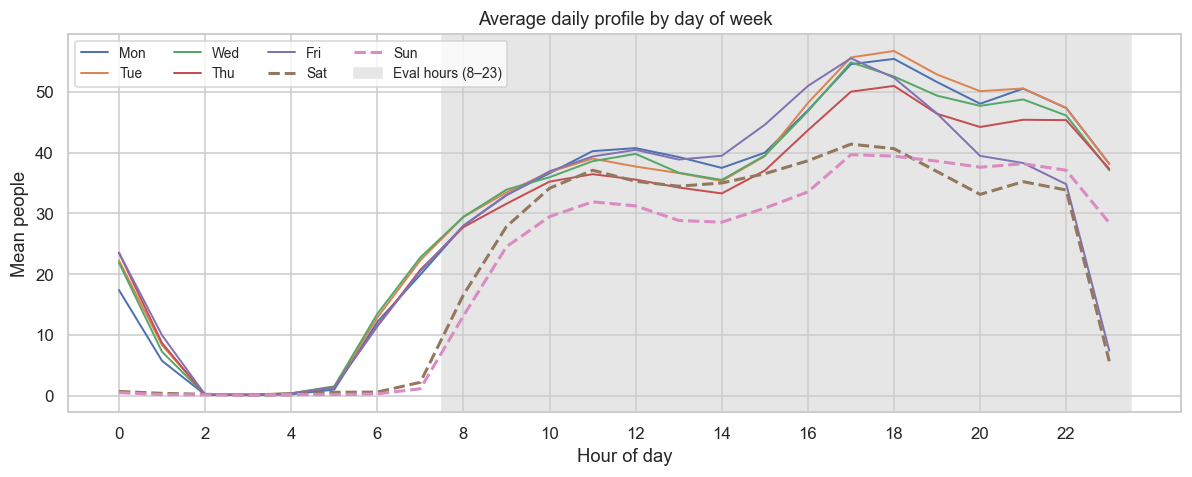

In [12]:
fig, ax = plt.subplots(figsize=(11, 4.5))
prof = hourly.groupby(["dow", "hour"])["y"].mean().unstack(0)
for d in range(7):
    ax.plot(prof.index, prof[d], label=DOW_NAMES[d], lw=2 if d >= 5 else 1.3,
            ls="--" if d >= 5 else "-")
ax.axvspan(min(EVAL_HOURS) - 0.5, max(EVAL_HOURS) + 0.5, color="0.9", zorder=0,
           label=f"Eval hours ({min(EVAL_HOURS)}–{max(EVAL_HOURS)})")
ax.set(title="Average daily profile by day of week", xlabel="Hour of day", ylabel="Mean people",
       xticks=range(0, 24, 2))
ax.legend(ncol=4, fontsize=9); fig.tight_layout(); save(fig, "05_daily_profile_by_dow")

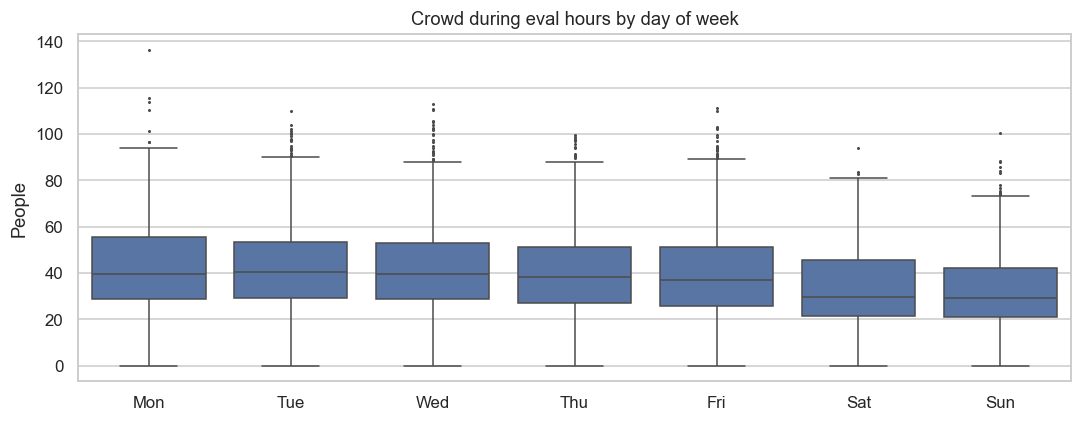

In [13]:
# Spread, not just the mean: busy-hour distribution by day of week
busy = hourly[hourly["hour"].isin(EVAL_HOURS)].copy()
busy["day"] = busy["dow"].map(dict(enumerate(DOW_NAMES)))

fig, ax = plt.subplots(figsize=(10, 4))
sns.boxplot(data=busy, x="day", y="y", order=DOW_NAMES, ax=ax, fliersize=1)
ax.set(title="Crowd during eval hours by day of week", xlabel="", ylabel="People")
fig.tight_layout(); save(fig, "06_box_by_dow")

## 4. Calendar effects

In [14]:
# is_holiday isn't carried into hourly by load_hourly, so pull it from the raw data
hourly["is_holiday"] = raw["is_holiday"].resample("h").max().reindex(hourly.index).ffill()

calendar_cols = ["is_during_semester", "is_start_of_semester", "is_weekend", "is_holiday"]
busy = hourly[hourly["hour"].isin(EVAL_HOURS) & hourly["y"].notna()]

summary = pd.concat(
    {c: busy.groupby(c)["y"].agg(["mean", "median", "count"]) for c in calendar_cols}
)
summary

mean     median  count
                     is_during_semester                             
is_during_semester   0.0                 25.699356  25.166667   2544
                     1.0                 44.612009  42.450000   5790
is_start_of_semester 0.0                 37.293579  35.166667   7633
                     1.0                 55.664490  54.800000    701
is_weekend           0.0                 41.362498  39.166667   5999
                     1.0                 32.355060  29.500000   2335
is_holiday           0.0                 38.901558  36.500000   8315
                     1.0                 11.381203  13.333333     19

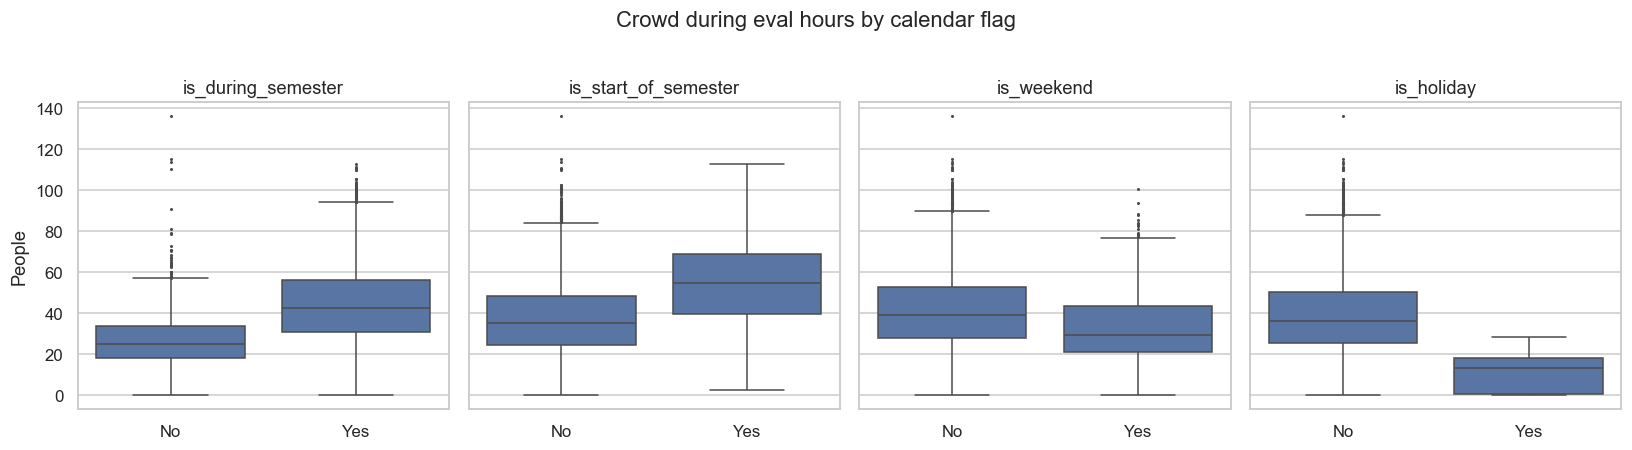

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4), sharey=True)
for ax, c in zip(axes, calendar_cols):
    sns.boxplot(data=busy, x=c, y="y", ax=ax, fliersize=1)
    ax.set(title=c, xlabel="", ylabel="People" if ax is axes[0] else "")
    ax.set_xticks([0, 1], ["No", "Yes"])
fig.suptitle("Crowd during eval hours by calendar flag", y=1.02)
fig.tight_layout(); save(fig, "07_box_calendar_flags")

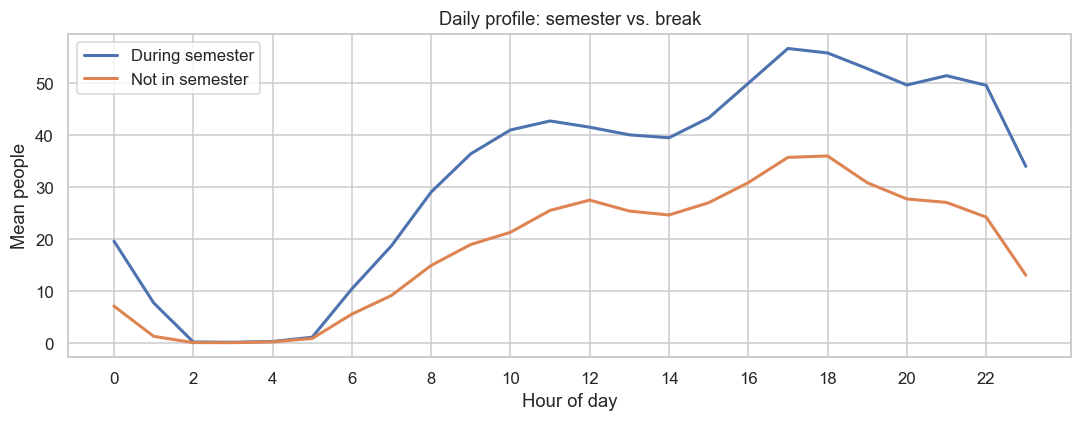

In [16]:
# Does semester change the shape of the day, or just the level?
fig, ax = plt.subplots(figsize=(10, 4))
for flag, label in [(1, "During semester"), (0, "Not in semester")]:
    p = hourly[hourly["is_during_semester"] == flag].groupby("hour")["y"].mean()
    ax.plot(p.index, p.values, lw=2, label=label)
ax.set(title="Daily profile: semester vs. break", xlabel="Hour of day", ylabel="Mean people",
       xticks=range(0, 24, 2))
ax.legend(); fig.tight_layout(); save(fig, "08_profile_semester")

## 5. Temperature

Correlation of y with temperature:
  all hours:  0.384
  eval hours: 0.307


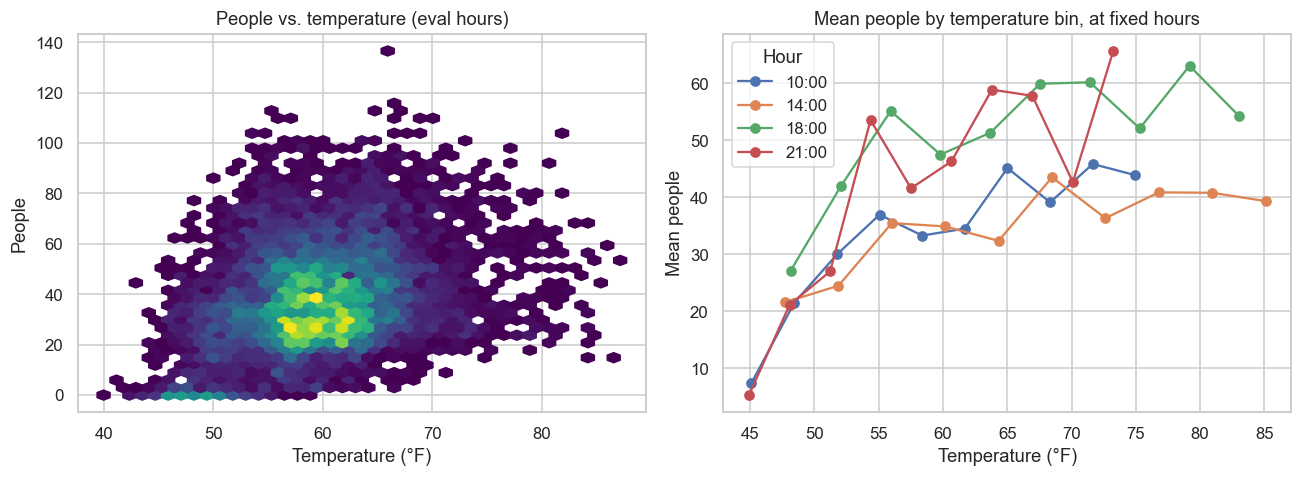

In [17]:
print("Correlation of y with temperature:")
print(f"  all hours:  {hourly[['y', 'temperature']].corr().iloc[0, 1]:.3f}")
print(f"  eval hours: {busy[['y', 'temperature']].corr().iloc[0, 1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].hexbin(busy["temperature"], busy["y"], gridsize=40, cmap="viridis", mincnt=1)
axes[0].set(title="People vs. temperature (eval hours)", xlabel="Temperature (°F)", ylabel="People")

# Temperature is confounded with hour of day, so also look within a fixed hour
for h in [10, 14, 18, 21]:
    sub = hourly[(hourly["hour"] == h) & hourly["y"].notna()]
    bins = pd.cut(sub["temperature"], bins=10)
    m = sub.groupby(bins, observed=True)["y"].mean()
    axes[1].plot([b.mid for b in m.index], m.values, marker="o", label=f"{h}:00")
axes[1].set(title="Mean people by temperature bin, at fixed hours", xlabel="Temperature (°F)",
            ylabel="Mean people")
axes[1].legend(title="Hour"); fig.tight_layout(); save(fig, "09_temperature")

## 6. Long-term trend and train/val/test splits

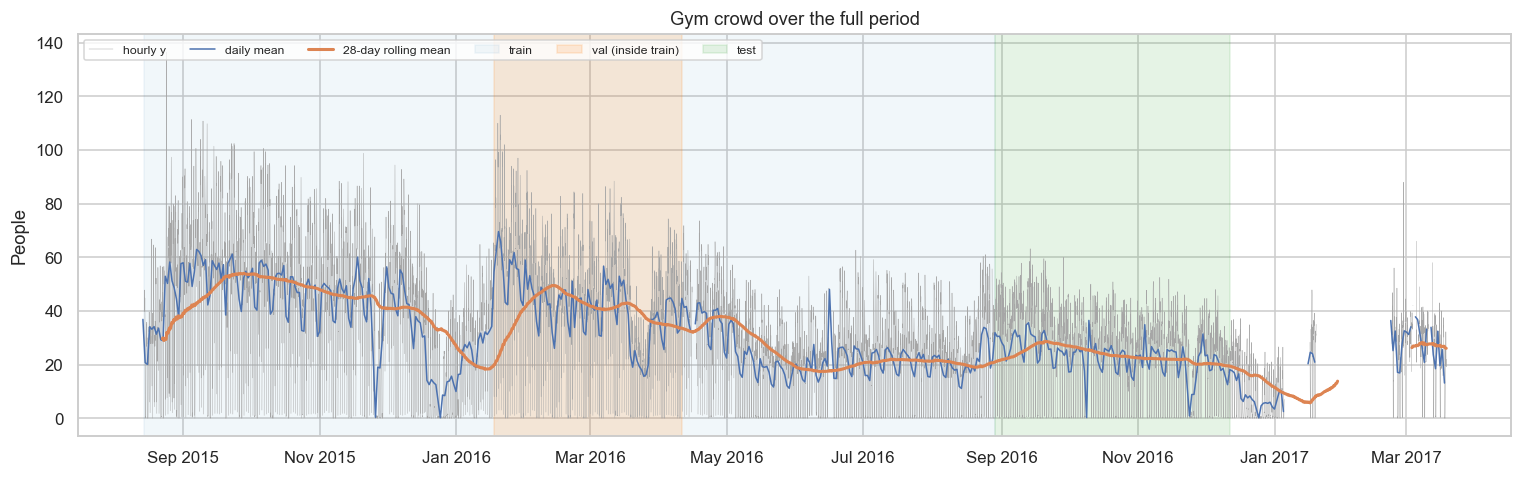

In [18]:
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(hourly.index, hourly["y"], lw=0.3, color="0.65", label="hourly y")
ax.plot(hourly["y"].resample("D").mean(), lw=1.0, label="daily mean")
ax.plot(hourly["y"].rolling(24 * 28, min_periods=24 * 7).mean(), lw=2, label="28-day rolling mean")

ax.axvspan(hourly.index.min(), pd.Timestamp(TRAIN_END), color="tab:blue", alpha=0.06, label="train")
ax.axvspan(pd.Timestamp(VAL_START), pd.Timestamp(VAL_END), color="tab:orange", alpha=0.15, label="val (inside train)")
ax.axvspan(pd.Timestamp(TEST_START), pd.Timestamp(TEST_END), color="tab:green", alpha=0.12, label="test")

ax.set(title="Gym crowd over the full period", ylabel="People")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(ncol=6, fontsize=8, loc="upper left"); fig.tight_layout(); save(fig, "10_timeline_splits")

In [19]:
train, val, test = split(hourly)
pd.DataFrame({
    name: {"start": d.index.min(), "end": d.index.max(), "hours": len(d),
           "missing y": int(d["y"].isna().sum()), "mean y": d["y"].mean(),
           "semester share": d["is_during_semester"].mean()}
    for name, d in [("train", train), ("val", val), ("test", test)]
}).T

,start,end,hours,missing y,mean y,semester share
train,2015-08-14 17:00:00,2016-08-28 23:00:00,9127,982,33.765563,0.625835
val,2016-01-18 00:00:00,2016-04-10 23:00:00,2016,278,41.548331,1.0
test,2016-08-29 00:00:00,2016-12-11 23:00:00,2520,80,23.071145,1.0


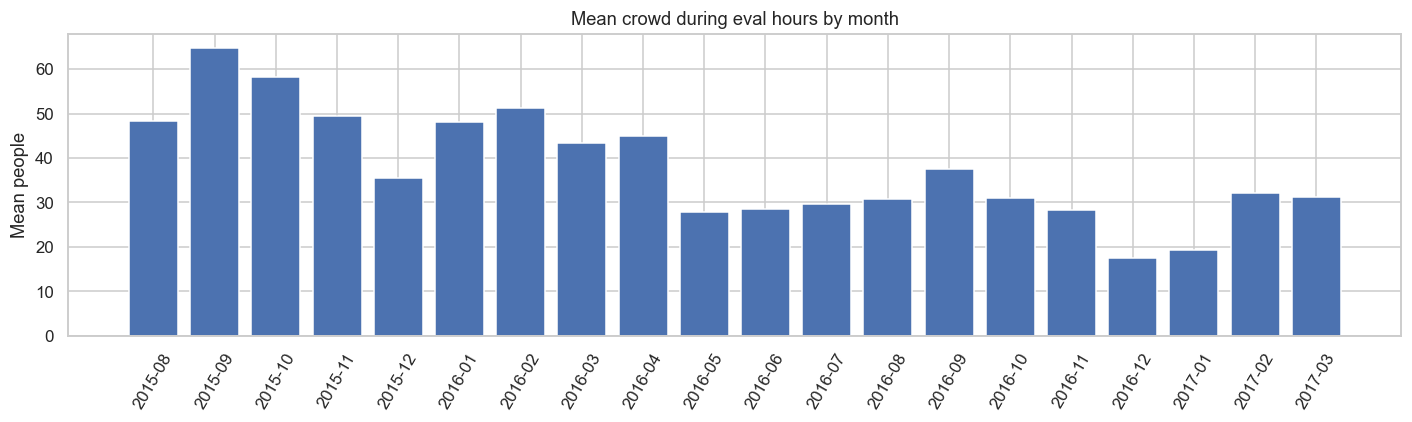

In [20]:
# Mean during eval hours by month, split by semester status
monthly = (busy.assign(month=busy.index.to_period("M"))
               .groupby("month")["y"].mean())

fig, ax = plt.subplots(figsize=(13, 4))
ax.bar(monthly.index.astype(str), monthly.values)
ax.set(title="Mean crowd during eval hours by month", ylabel="Mean people")
ax.tick_params(axis="x", rotation=60)
fig.tight_layout(); save(fig, "11_monthly_mean")

## 7. Autocorrelation

ACF is computed by hand on `y`, keeping only pairs where both values are present, because `y` still has NaN gaps. PACF comes from the Durbin–Levinson recursion on that ACF.

In [21]:
def acf_pairwise(s, max_lag):
    x = s.to_numpy(float)
    out = np.empty(max_lag + 1)
    out[0] = 1.0
    for k in range(1, max_lag + 1):
        a, b = x[k:], x[:-k]
        ok = ~np.isnan(a) & ~np.isnan(b)
        out[k] = np.corrcoef(a[ok], b[ok])[0, 1]
    return out

def pacf_from_acf(r, max_lag):
    # Durbin-Levinson recursion
    pacf = np.zeros(max_lag + 1); pacf[0] = 1.0
    phi = np.zeros((max_lag + 1, max_lag + 1))
    phi[1, 1] = pacf[1] = r[1]
    for k in range(2, max_lag + 1):
        num = r[k] - np.dot(phi[k - 1, 1:k], r[1:k][::-1])
        den = 1 - np.dot(phi[k - 1, 1:k], r[1:k])
        phi[k, k] = pacf[k] = num / den
        phi[k, 1:k] = phi[k - 1, 1:k] - phi[k, k] * phi[k - 1, 1:k][::-1]
    return pacf

MAX_LAG = 24 * 15
r = acf_pairwise(train["y"], MAX_LAG)
p = pacf_from_acf(r, 200)
n_eff = train["y"].notna().sum()
band = 1.96 / np.sqrt(n_eff)

for lag in [1, 2, 24, 168, 336]:
    print(f"ACF lag {lag:>3}: {r[lag]:.3f}")

ACF lag   1: 0.910
ACF lag   2: 0.760
ACF lag  24: 0.880
ACF lag 168: 0.843
ACF lag 336: 0.775


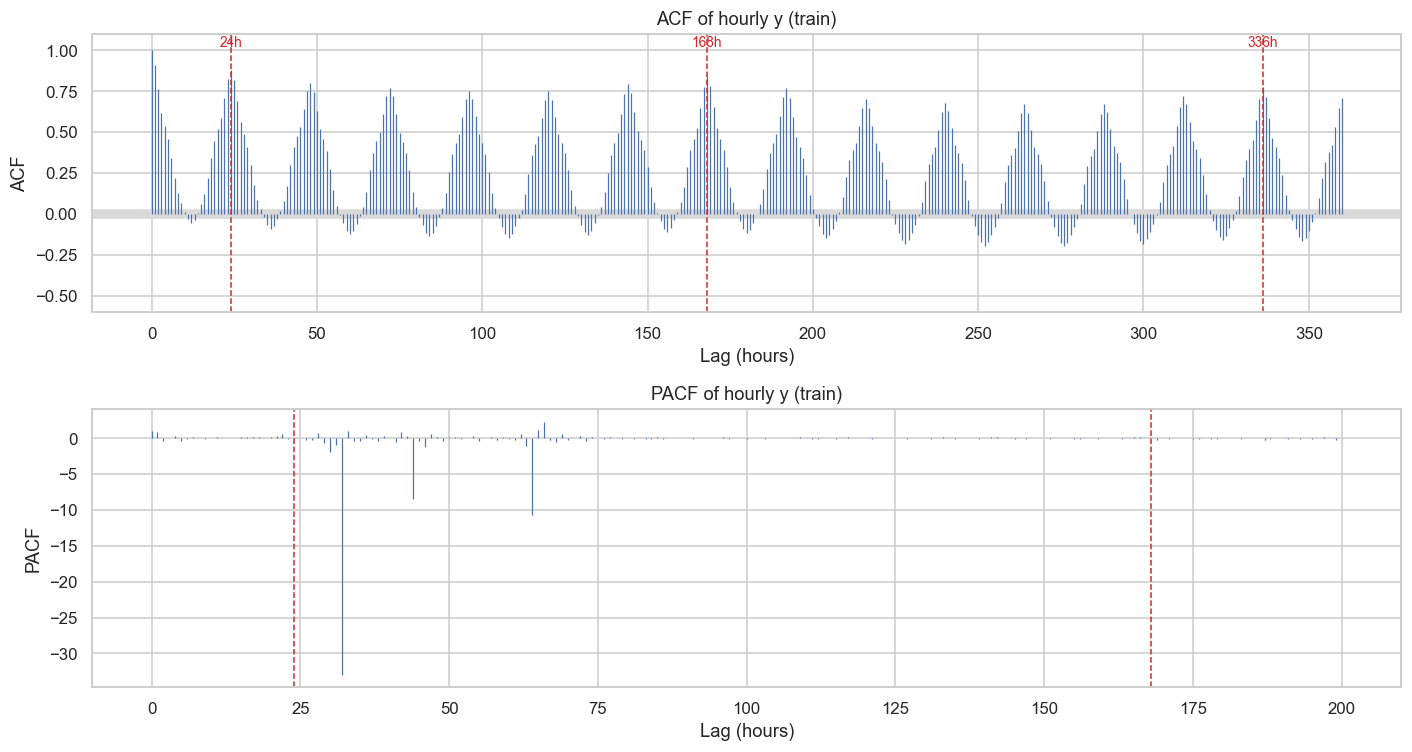

In [22]:
fig, axes = plt.subplots(2, 1, figsize=(13, 7))

axes[0].vlines(range(MAX_LAG + 1), 0, r, lw=0.8)
for lag in [24, 168, 336]:
    axes[0].axvline(lag, color="tab:red", ls="--", lw=1)
    axes[0].text(lag, 1.02, f"{lag}h", color="tab:red", ha="center", fontsize=9)
axes[0].axhspan(-band, band, color="0.85")
axes[0].set(title="ACF of hourly y (train)", xlabel="Lag (hours)", ylabel="ACF", ylim=(-0.6, 1.1))

axes[1].vlines(range(len(p)), 0, p, lw=0.8)
for lag in [24, 168]:
    axes[1].axvline(lag, color="tab:red", ls="--", lw=1)
axes[1].axhspan(-band, band, color="0.85")
axes[1].set(title="PACF of hourly y (train)", xlabel="Lag (hours)", ylabel="PACF")
fig.tight_layout(); save(fig, "12_acf_pacf")

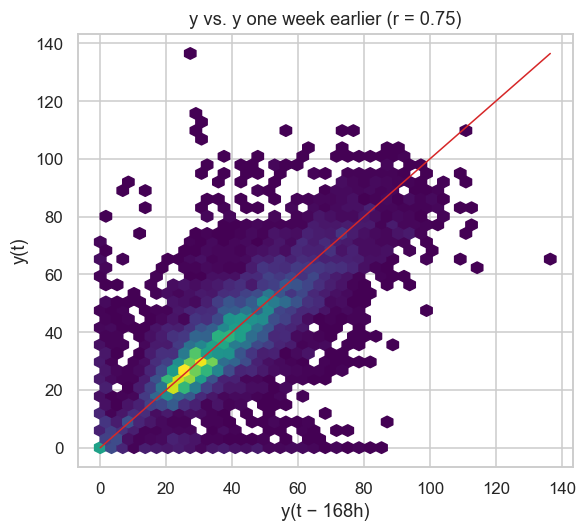

In [23]:
# Week-over-week check: how well does last week's value predict this hour? (seasonal-naive intuition)
lagged = pd.DataFrame({"y": hourly["y"], "y_lag168": hourly["y"].shift(168)}).dropna()
lagged = lagged[lagged.index.hour.isin(EVAL_HOURS)]

fig, ax = plt.subplots(figsize=(5.5, 5))
ax.hexbin(lagged["y_lag168"], lagged["y"], gridsize=40, cmap="viridis", mincnt=1)
lim = [0, lagged.max().max()]
ax.plot(lim, lim, color="tab:red", lw=1)
ax.set(title=f"y vs. y one week earlier (r = {lagged.corr().iloc[0, 1]:.2f})",
       xlabel="y(t − 168h)", ylabel="y(t)")
fig.tight_layout(); save(fig, "13_lag168_scatter")